<a href="https://colab.research.google.com/github/lamia-khd/react-router/blob/master/correlation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


```markdown
# Setup and Imports
We start by importing the required libraries and loading the dataset from Google Drive.
```

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/datasets/medical_dataset.csv')
display(df.head())

,patient_id,age,sex,bmi,sbp,cholesterol,smoking,coffee_cups,stress_level,heart_risk
0,1,65,M,26.9,152,238,0,1,2,37.8
1,2,73,F,26.1,153,236,1,3,2,41.3
2,3,67,F,21.5,163,226,2,4,3,58.7
3,4,39,F,23.2,135,256,2,4,1,36.9
4,5,34,M,28.7,134,213,2,4,3,47.8


```markdown
## Part 0 – Exploring the data
### Question 1 — First look
1. Let's display the shape of the dataset, types of each column, missing values, and descriptive statistics.
```

In [8]:
print("Dataset Shape:", df.shape)
print("\nColumn Types:")
print(df.dtypes)
print("\nMissing Values per column:")
print(df.isna().sum())

display(df.describe().T)

Dataset Shape: (100, 10)

Column Types:
patient_id        int64
age               int64
sex              object
bmi             float64
sbp               int64
cholesterol       int64
smoking           int64
coffee_cups       int64
stress_level      int64
heart_risk      float64
dtype: object

Missing Values per column:
patient_id      0
age             0
sex             0
bmi             0
sbp             0
cholesterol     0
smoking         0
coffee_cups     0
stress_level    0
heart_risk      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
patient_id,100.0,50.500,29.011492,1.0,25.750,50.50,75.250,100.0
age,100.0,53.040,11.455597,25.0,44.000,53.00,61.250,80.0
bmi,100.0,25.861,3.793586,18.0,23.475,26.05,28.325,38.6
sbp,100.0,149.020,11.014206,124.0,141.000,148.50,156.250,176.0
cholesterol,100.0,231.930,22.714413,175.0,217.000,233.50,248.250,278.0
smoking,100.0,0.960,0.863631,0.0,0.000,1.00,2.000,2.0
coffee_cups,100.0,2.540,1.298173,0.0,1.000,2.00,4.000,5.0
stress_level,100.0,2.520,1.058682,1.0,2.000,2.00,3.000,5.0
heart_risk,100.0,41.522,11.152674,16.9,33.775,43.35,48.775,70.9


```markdown
2. **Variable Classification & Appropriate Measures with `heart_risk`**:
- **age**: Continuous quantitative (ratio scale) $\rightarrow$ Pearson / Spearman / Kendall correlation.
- **smoking**: Categorical Ordinal (or Nominal) $\rightarrow$ Spearman rank correlation, Kendall's $\tau$, or Correlation Ratio $\eta$ (if treated as groups).
- **stress_level**: Ordinal discrete quantitative $\rightarrow$ Spearman rank correlation / Kendall's $\tau$.
- **sex**: Nominal qualitative $\rightarrow$ Correlation ratio $\eta$ / Point-biserial correlation.
```

```markdown
### Summary Table: Variable Nature & Appropriate Correlation Measures
| Variable | Nature of Variable | Appropriate Measures with `heart_risk` |
| :--- | :--- | :--- |
| **age** | Continuous quantitative | Pearson's $r$, Spearman's $\rho$, or Kendall's $\tau$ |
| **smoking** | Ordinal (categorical) | Spearman's $\rho$, Kendall's $\tau$, or Correlation Ratio $\eta$ |
| **stress_level** | Discrete quantitative / Ordinal | Spearman's $\rho$ or Kendall's $\tau$ |
| **sex** | Nominal qualitative | Correlation Ratio $\eta$ |
```

```markdown
## Part 1 – Pearson correlation
### Question 2 — Visual intuition
Let's plot `sbp` (Systolic Blood Pressure) against `age` to inspect the visual trend.
```

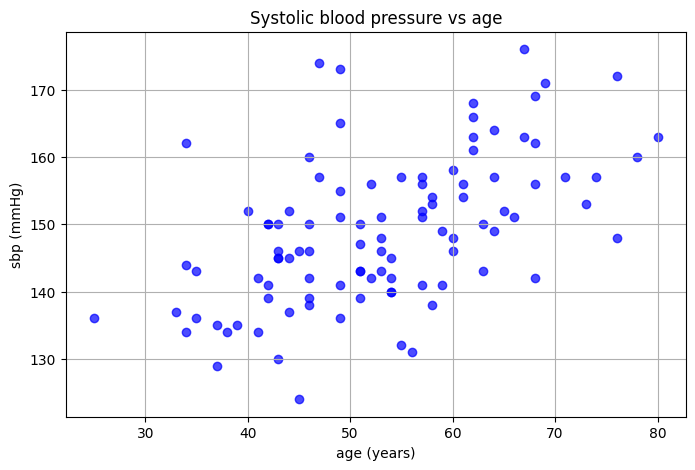

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df.age, df.sbp, alpha=0.7, color='b')
plt.xlabel("age (years)")
plt.ylabel("sbp (mmHg)")
plt.title("Systolic blood pressure vs age")
plt.grid(True)
plt.show()

```markdown
### Interpretation of Scatter Plot (Question 2)
- **Expectation**: There is a clear, upward linear trend between `age` and systolic blood pressure (`sbp`).
- **Strength & Sign**: We expect a **moderate-to-strong positive** correlation because as age increases, the systolic blood pressure also increases.
- **Linearity**: A straight line looks highly appropriate for modeling this relationship.
```

```markdown
### Question 3 — Pearson by hand verification
We will define the data points for the first 8 patients to verify our manual computation values.
```

In [10]:
x = np.array([65, 73, 67, 39, 34, 53, 63, 59])
y = np.array([152, 153, 163, 135, 134, 151, 150, 141])

mean_x = x.mean()
mean_y = y.mean()

dx = x - mean_x
dy = y - mean_y
Sxy = np.sum(dx * dy)
Sxx = np.sum(dx ** 2)
Syy = np.sum(dy ** 2)
r = Sxy / np.sqrt(Sxx * Syy)

print(f"mean x = {mean_x:.2f}, mean y = {mean_y:.2f}")
print(f"Sxx = {Sxx:.2f}, Syy = {Syy:.2f}, Sxy = {Sxy:.2f}")
print(f"Pearson r = {r:.4f}")

mean x = 56.62, mean y = 147.38
Sxx = 1327.88, Syy = 689.88, Sxy = 802.12
Pearson r = 0.8381


```markdown
### Verification of Pearson By Hand (Question 3)
- **Mean age ($\bar{x}$)**: $56.62$
- **Mean sbp ($\bar{y}$)**: $147.38$
- **Sxx**: $1327.88$, **Syy**: $689.88$, **Sxy**: $802.12$
- **Pearson $r$**: $0.8381$
- **Conclusion**: The manual calculation matches the code exactly, indicating a very strong positive linear correlation in this subset of 8 patients.
```

```markdown
### Question 4 — Pearson on the full dataset
Computing Pearson correlation and its p-value, as well as $r^2$ for (age, sbp) and (bmi, sbp).
```

In [11]:
for a, b in [("age", "sbp"), ("bmi", "sbp")]:
    r, p = stats.pearsonr(df[a], df[b])
    print(f"{a} vs {b}: r = {r:.3f}, r^2 = {r**2:.3f}, p = {p:.2e}")

age vs sbp: r = 0.541, r^2 = 0.293, p = 5.98e-09
bmi vs sbp: r = 0.455, r^2 = 0.207, p = 1.96e-06


```markdown
### Pearson Correlation Analysis on the Full Dataset (Question 4)
1. **`age` vs `sbp`**:
   - $r = 0.541$ (p-value = $5.98 \times 10^{-9}$)
   - $r^2 = 0.293$
   - **Interpretation**: There is a moderate positive correlation. $r^2 = 0.293$ means that **$29.3\%$** of the variation in systolic blood pressure is explained by age in this sample.
2. **`bmi` vs `sbp`**:
   - $r = 0.455$ (p-value = $1.96 \times 10^{-6}$)
   - $r^2 = 0.207$
   - **Interpretation**: There is a moderate positive correlation. $r^2 = 0.207$ means that **$20.7\%$** of the variation in systolic blood pressure is explained by the Body Mass Index.
- Both relationships are statistically highly significant ($p < 0.05$).
```

```markdown
## Part 2 – Spearman rank correlation
### Question 5 — Spearman by hand verification
Using the same 8 patients, let's look at the ranks and Spearman rank correlation coefficient.
```

In [12]:
print("rank x:", stats.rankdata(x))
print("rank y:", stats.rankdata(y))
rho, p_val = stats.spearmanr(x, y)
print("rho =", round(rho, 4))

rank x: [6. 8. 7. 2. 1. 3. 5. 4.]
rank y: [6. 7. 8. 2. 1. 5. 4. 3.]
rho = 0.9048


```markdown
### Spearman Rank Correlation Analysis (Question 5)
- **Spearman $\rho$**: $0.9048$
- **Comparison**: Spearman's $\rho$ ($0.9048$) is larger than Pearson's $r$ ($0.8381$). This indicates that the relationship is highly monotonic but has a slight non-linear shape, which Spearman's rank order captures better than the linear Pearson coefficient.
```

```markdown
## Part 4 – The correlation matrix
### Question 8 — Pearson matrix
We compute the full Pearson correlation matrix for numerical parameters and plot it as an annotated heatmap.
```

               age   bmi   sbp  cholesterol  coffee_cups  stress_level  \
age           1.00  0.17  0.54         0.28        -0.04          0.15   
bmi           0.17  1.00  0.46         0.42        -0.08          0.03   
sbp           0.54  0.46  1.00         0.20         0.17          0.15   
cholesterol   0.28  0.42  0.20         1.00         0.12          0.18   
coffee_cups  -0.04 -0.08  0.17         0.12         1.00          0.27   
stress_level  0.15  0.03  0.15         0.18         0.27          1.00   
heart_risk    0.56  0.39  0.55         0.49         0.47          0.28   

              heart_risk  
age                 0.56  
bmi                 0.39  
sbp                 0.55  
cholesterol         0.49  
coffee_cups         0.47  
stress_level        0.28  
heart_risk          1.00  


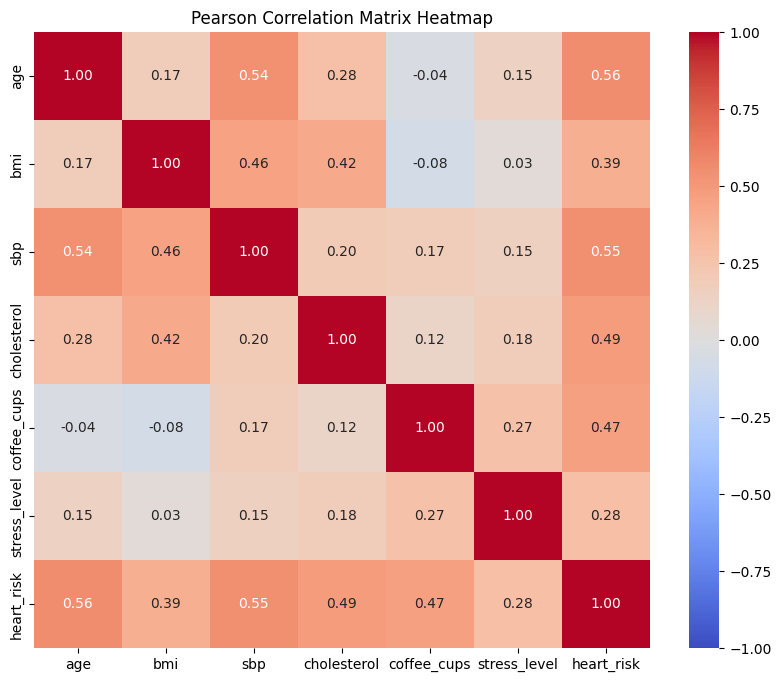

In [13]:
num_cols = ["age", "bmi", "sbp", "cholesterol", "coffee_cups", "stress_level", "heart_risk"]
corr = df[num_cols].corr(method="pearson")
print(corr.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Correlation Matrix Heatmap")
plt.show()

```markdown
### Pearson Correlation Matrix Interpretations (Question 8)
- **Why is the matrix symmetric?**
  The correlation between Variable $A$ and Variable $B$ is identical to that between $B$ and $A$ ($r(A,B) = r(B,A)$).
- **Why is its diagonal equal to 1?**
  Any variable compared with itself has a perfect positive linear relationship ($r = 1.00$).
- **Strongest & Weakest Correlation**:
  - **Strongest pair**: `age` vs `heart_risk` ($r = 0.56$) and `sbp` vs `heart_risk` ($r = 0.55$).
  - **Closest to 0**: `age` vs `coffee_cups` ($r = -0.04$).
- **Most Correlated with `heart_risk`**:
  - `age` ($r = 0.56$), `sbp` ($r = 0.55$), and `cholesterol` ($r = 0.49$).
- **Interpretation of (`coffee_cups`, `heart_risk`) cell**:
  - There is a moderate positive correlation ($r = 0.47$) between coffee consumption and cardiac risk in this simulated dataset.
```

```markdown
## Part 5 – The correlation ratio $\eta$
### Question 9 — Eta by hand verification
We compute $\eta^2$ and $\eta$ for the defined smoking groups.
```

In [14]:
groups = {0: [37.8, 42.6, 22.6], 1: [41.3, 36.3, 54.5], 2: [58.7, 36.9, 47.8]}
allv = np.concatenate([np.array(v) for v in groups.values()])
gm = allv.mean()
ssb = sum(len(v) * (np.mean(v) - gm) ** 2 for v in groups.values())
sst = np.sum((allv - gm) ** 2)

print("group means:", {k: round(np.mean(v), 2) for k, v in groups.items()}, "overall:", round(gm, 2))
print("SSB =", round(ssb, 2), " SST =", round(sst, 2))
print("eta^2 =", round(ssb / sst, 3), " eta =", round(np.sqrt(ssb / sst), 3))

group means: {0: np.float64(34.33), 1: np.float64(44.03), 2: np.float64(47.8)} overall: 42.06
SSB = 289.63  SST = 922.1
eta^2 = 0.314  eta = 0.56


```markdown
### Eta Correlation Ratio Analysis (Question 9)
- **Group Means**:
  - Never Smoker (0): $34.33$
  - Former Smoker (1): $44.03$
  - Current Smoker (2): $47.80$
  - **Overall Mean**: $42.06$
- **Sums of Squares**: $SS_{\text{between}} = 289.63$, $SS_{\text{total}} = 922.10$
- **Results**: $\eta^2 = 0.314$ and $\eta = 0.560$
- **Interpretation**: $\eta^2 = 0.314$ indicates that **$31.4\%$** of the variance in patient `heart_risk` is explained by their smoking status group in this sample.
```